![Banner](../../../../Images/Banner/05_geostat/04_specialized_kriging.png)

# Specialized Kriging



Ordinary kriging answers one question. At a place you did not sample, it returns the linear unbiased estimate of the measured variable, and the error variance of that estimate, from a single variogram. Soil metals, ore grade, and contaminant concentrations often ask a different question. A probability of exceeding a cutoff. A grade in a volume, where continuity along a borehole is shorter than continuity between boreholes. A probability that can use a cheap, uncertain proxy where the expensive assay is missing. A nonlinear function of each assay. The part of a map that lives at one spatial scale.

This notebook is the map for those five estimators in GeoLattice. It writes the change each one makes to the ordinary-kriging system, then runs all five on eighteen samples and one target. The five notebooks that follow keep one estimator each and carry it through a survey.

Six notebooks change the ordinary-kriging system so it can return a probability, a block grade, a soft assay, a skewed histogram, or one scale of a nested variogram.

- **Specialized Kriging.** This notebook. All five estimators on eighteen samples and one target.
- **Indicator Kriging.** Meuse zinc. A cutoff variogram, a Brier score, and an E-type map.
- **3-D Kriging (KT3D).** GSLIB `cluster.dat`, then synthetic boreholes. Anisotropy, octant search, block support, and a depth trend.
- **Soft Kriging.** Jura cadmium, with zinc as a dense proxy and most cadmium assays held out.
- **Disjunctive Kriging.** Jura cadmium. Gaussian anamorphosis, Hermite orders, and exceedance maps beside ordinary kriging.
- **Factorial Kriging.** Jura cadmium. A nested variogram split into short-range, long-range, and nugget-filtered maps.

Library: `geolattice.geostatistics`




## Table of Contents

- [What this chapter covers](#what-this-chapter-covers)
1. [Notebooks in this chapter](#1-notebooks-in-this-chapter)
2. [What changes from ordinary kriging](#2-what-changes-from-ordinary-kriging)
3. [Indicator kriging](#indicator-kriging)
4. [Kriging in three dimensions](#kriging-in-three-dimensions)
5. [Soft kriging](#soft-kriging)
6. [Disjunctive kriging](#disjunctive-kriging)
7. [Factorial kriging](#factorial-kriging)
8. [Specialized kriging in GeoLattice](#specialized-kriging-in-geolattice)
9. [Python setup](#python-setup)
10. [Eighteen samples and one target](#eighteen-samples-and-one-target)
11. [Five answers at one target](#five-answers-at-one-target)
12. [How to read the five answers](#how-to-read-the-five-answers)
13. [Where the next notebooks go](#where-the-next-notebooks-go)
14. [Resources](#resources)
    - 14.1 [The paper or program behind each estimator](#the-paper-or-program-behind-each-estimator)
    - 14.2 [Textbooks that cover more than one of them](#textbooks-that-cover-more-than-one-of-them)
    - 14.3 [In this library](#in-this-library)



## Overview

Write the ordinary-kriging predictor at an unsampled location $\mathbf{x}_0$ as

$$
\hat Z(\mathbf{x}_0) = \sum_{i=1}^{n} \lambda_i \, Z(\mathbf{x}_i),
$$

with weights from the system in the [kriging introduction](../05_02_kriging/05_02_00_introduction_kriging.ipynb):

$$
\begin{bmatrix}
\mathbf{C} & \mathbf{1} \\
\mathbf{1}^{\top} & 0
\end{bmatrix}
\begin{bmatrix}
\boldsymbol{\lambda} \\
\mu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_0 \\
1
\end{bmatrix}.
$$

$\mathbf{C}$ holds covariances among the samples, $\mathbf{c}_0$ holds covariances between the samples and the target, and $\mu$ enforces $\sum \lambda_i = 1$ so an unknown constant mean cancels. The kriging variance is $C(0) - \boldsymbol{\lambda}^{\top}\mathbf{c}_0 - \mu$.

The five estimators in this chapter keep a system of that shape. Each one changes the rows that enter $\mathbf{C}$, the right-hand side $\mathbf{c}_0$, or the numbers the weights multiply.

| Estimator | Weights multiply | Right-hand side | What comes back |
|---|---|---|---|
| Indicator kriging | $0/1$ indicators at a cutoff | The indicator covariance | $P[Z(\mathbf{x}_0) \ge z_k]$, clipped to $[0, 1]$ |
| 3-D kriging (`kt3d`) | The grade, at $(x, y, z)$ | Covariance along an anisotropy ellipsoid | A grade, a variance, and optionally a block average |
| Soft kriging | Hard indicators and soft probabilities | The hard covariance, rescaled by one coefficient $B$ | A probability that uses both data types |
| Disjunctive kriging | Hermite polynomials of the normal score | $\rho(h)^n$ at Hermite order $n$ | A nonlinear grade, and any cutoff probability from the same fit |
| Factorial kriging | The grade | Covariance of **one** nested structure, with $\sum \lambda_i = 0$ | That scale alone: short-range, long-range, or the nugget |

Ordinary kriging of the raw grade remains the reference. The worked example below reports it beside the five calls, from a spherical variogram that is set rather than fitted, the same device as the kriging introduction.


---

## Indicator kriging

For a cutoff $z_k$, code each sample as an exceedance indicator

$$
I(\mathbf{x}; z_k) =
\begin{cases}
1, & Z(\mathbf{x}) \ge z_k, \\
0, & Z(\mathbf{x}) < z_k.
\end{cases}
$$

The expectation of that indicator is the exceedance probability, $\mathbb{E}[I(\mathbf{x}_0; z_k)] = P[Z(\mathbf{x}_0) \ge z_k]$. Ordinary kriging of the $0/1$ values is therefore a direct estimate of the probability. `IndicatorKriging` solves the ordinary-kriging system with the indicator covariance $C_I$ and clips the result to $[0, 1]$.

Each cutoff has its own variogram. The theoretical sill of a binary indicator is $p_k(1-p_k)$, where $p_k = P[Z \ge z_k]$. A high-grade streak can be shorter, or more nuggety, than the mid-grade background, so each probability map keeps its own variogram.

A stack of cutoffs $z_1 < \cdots < z_K$ is a discrete conditional distribution. Its mean is the **E-type** estimate,

$$
Z_E(\mathbf{x}_0) = \int_0^{\infty} P[Z(\mathbf{x}_0) \ge z] \, dz,
$$

evaluated by trapezoid rule in `compute_etype_from_probabilities`. Nothing in the separate kriging systems forces the probabilities to decrease as the cutoff rises. The indicator notebook is where that order relation, the per-cutoff variogram, and the E-type map are checked on Meuse zinc.

`IndicatorKriging` is two-dimensional and pointwise. The class stores the samples in `fit` and takes the cutoffs, with an optional dict of `(nugget, partial sill, range)` per cutoff, in `predict`.


---

## Kriging in three dimensions

`kt3d` is a Python port of GSLIB's `kt3d` (Deutsch & Journel, 1998). The predictor is still a weighted sum of nearby grades. The distance that enters the covariance is the anisotropic distance

$$
h(\mathbf{d}) = \lVert R \, \mathbf{d} \rVert_2,
\qquad
\mathbf{d} = \mathbf{x}_i - \mathbf{x}_0,
$$

where $R$ rotates $\mathbf{d}$ onto the axes of an ellipsoid and rescales those axes by the major, minor-horizontal, and vertical ranges. A transformed distance of 1 is one range in every direction. For borehole data the vertical range is the short one: grade can change quickly with depth and stay smooth between holes.

`ktype` selects the mean model. `'ordinary'` is the unknown constant mean above. `'simple'` uses a known mean. A polynomial drift in $x$, $y$, $z$, and their products is kriging with a trend. `'external_drift'` ties the mean to a secondary variable known at the samples and at the target. `'locally_varying_mean'` plugs in a known local mean and kriges the residual as in simple kriging.

Two further controls matter once the data are a volume. The search is an ellipsoid (`search_radius`, `search_radius2`, `search_radius3`) with a minimum and a maximum number of neighbours, and an optional cap of `noct` neighbours per octant so one cluster of holes cannot fill the whole neighbourhood. Block kriging replaces each point-to-target covariance with the average covariance between the sample and a grid of points inside the block. Averaging over a volume smooths the estimate and lowers the kriging variance. That support effect is worked in the 3-D notebook, on synthetic boreholes. The call here is ordinary point kriging, so the only change from the map-view system is the third coordinate and the vertical range.


---

## Soft kriging

Indicator kriging treats every sample as exact: the indicator is 0 or 1. A certified assay often is exact and sparse, while a cheaper proxy, a portable sensor, a geophysical grid, another metal measured at the same campaign, is dense and only correlated with the cutoff. **Soft data** are probabilities $F(\mathbf{u}) \in [0, 1]$, an estimate of $P[Z(\mathbf{u}) \ge z]$ at locations that may have no assay.

A full cokriging of the hard indicator $I$ and the soft probability $F$ needs a cross-variogram. The Markov-Bayes model of Zhu & Journel (1993) replaces that cross-variogram with one calibration coefficient

$$
B = \frac{\mathrm{Cov}(I, F)}{\mathrm{Var}(F)},
$$

estimated from co-located pairs by `markov_bayes_calibrate`. Under the Markov screening assumption the covariances collapse to rescalings of the hard-indicator covariance $C_H$:

$$
C_{HH}(h) = C_H(h),
\qquad
C_{HS}(h) = B \, C_H(h),
\qquad
C_{SS}(h) = B^{2} \, C_H(h).
$$

$B$ near 1 means the proxy carries almost as much information as an assay. $B$ near 0 means the soft rows drop out, and the estimator falls back to ordinary indicator kriging of the hard data. `SoftKriging` then solves one ordinary-kriging system whose weights cover both data types:

$$
\hat P(\mathbf{u}_0)
  = \sum_i \lambda_{H,i} \, I(\mathbf{u}_i)
  + \sum_j \lambda_{S,j} \, F(\mathbf{u}_j),
\qquad
\sum_i \lambda_{H,i} + \sum_j \lambda_{S,j} = 1.
$$

The estimate is clipped to $[0, 1]$. When the proxy is a continuous measurement, `fit_soft_probability_model` turns it into $F$ with a logistic regression fitted on the hard indicators. The soft-kriging notebook does that calibration on Jura zinc against a cadmium cutoff of 1 mg/kg. The example below sets $B$ and a fixed logistic, so the weights are the solution of a known system.


---

## Disjunctive kriging

Ordinary kriging is the best predictor inside the class of linear combinations of the data. The best predictor without that restriction is the conditional expectation $\mathbb{E}[Z(\mathbf{x}_0) \mid \text{data}]$, which needs the full multivariate distribution. Disjunctive kriging (Matheron, 1976) sits between the two. It is the best predictor of the form

$$
\hat Z_{\mathrm{DK}}(\mathbf{x}_0) = \sum_{i=1}^{n} f_i\bigl(Z(\mathbf{x}_i)\bigr),
$$

a separate function of each sample, under one model that makes those functions computable.

The model has two steps. A Gaussian anamorphosis writes $Z(\mathbf{x}) = \varphi\bigl(Y(\mathbf{x})\bigr)$ with $Y$ standard normal, the same normal-score transform `nscore` uses for sequential Gaussian simulation. The anamorphosis is expanded in orthonormal Hermite polynomials,

$$
\varphi(y) = \sum_{n=0}^{N} \varphi_n \, H_n(y),
\qquad
\varphi_n = \mathbb{E}\bigl[Z \, H_n(Y)\bigr].
$$

The spatial assumption is the bi-Gaussian model: every pair $\bigl(Y(\mathbf{x}), Y(\mathbf{x}')\bigr)$ is bivariate normal with correlation $\rho(h)$. Hermite polynomials then diagonalize the covariance,

$$
\mathbb{E}\bigl[H_n\bigl(Y(\mathbf{x})\bigr) \, H_m\bigl(Y(\mathbf{x}')\bigr)\bigr]
  = \delta_{nm} \, \rho(h)^{n}.
$$

Different orders are uncorrelated at every lag, so each order is simple-kriged on its own, with covariance $\rho(h)^n$, and the grade is the sum

$$
\hat Z_{\mathrm{DK}}(\mathbf{x}_0)
  = \sum_{n=0}^{N} \varphi_n \, \bigl[H_n\bigl(Y(\mathbf{x}_0)\bigr)\bigr]^{*}_{\mathrm{SK}}.
$$

Order $n = 0$ is the mean. The orders $n \ge 2$ are the nonlinear part. The same kriged components estimate a cutoff probability, with indicator coefficients $\chi_n(y_c)$ in place of $\varphi_n$. `predict` returns the grade. `predict_proba` returns the probabilities. Both come from one fit.

`DisjunctiveKriging` fits the variogram of $Y$ itself. On a short sample that fit can differ from the variogram you would write down for $Z$, and the truncated Hermite series can account for slightly more or slightly less than $\mathrm{Var}(Z)$. The attribute `explained_variance_ratio_` is that fraction. The disjunctive notebook is where the anamorphosis, the truncation, and a comparison with ordinary kriging are examined on Jura cadmium. The call below uses six Hermite orders so the shape of the estimator is visible on eighteen points.


---

## Factorial kriging

A fitted variogram is usually nested: a nugget plus two or more bounded structures, each with its own range. Ordinary kriging uses the sum. Factorial kriging (Matheron, 1982) treats the structures as mutually uncorrelated zero-mean factors,

$$
Z(\mathbf{x}) = m + Z_1(\mathbf{x}) + \cdots + Z_S(\mathbf{x}),
\qquad
\gamma(h) = \sum_u \gamma_u(h).
$$

To estimate one factor $Z_v(\mathbf{x}_0)$, the left-hand side stays the ordinary-kriging matrix of the **full** covariance $C = \sum_u C_u$. The right-hand side changes to the covariance of structure $v$ alone, and the unbiasedness constraint changes from 1 to 0, because a zero-mean factor has mean zero and the unknown $m$ has to be filtered out:

$$
\begin{bmatrix}
\mathbf{C} & \mathbf{1} \\
\mathbf{1}^{\top} & 0
\end{bmatrix}
\begin{bmatrix}
\boldsymbol{\lambda}^{v} \\
\mu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_{v} \\
0
\end{bmatrix}.
$$

`FactorialKriging.extract` implements that switch.

| `factor` | Constraint | What it estimates |
|---|---|---|
| `'total'` | $\sum \lambda_i = 1$ | Ordinary kriging of $Z$ |
| `'denoised'` | $\sum \lambda_i = 1$ | $Z$ with the nugget removed from the target covariance |
| `'nugget'` or `0` | $\sum \lambda_i = 0$ | The nugget component |
| an integer $k \ge 1$ | $\sum \lambda_i = 0$ | Structure $k$ alone |
| a sequence of integers | $\sum \lambda_i = 0$ | The sum of those structures |

Because the system is linear in the right-hand side, structures that share the constraint $\sum \lambda_i = 0$ add: `extract([1, 2])` equals `extract(1) + extract(2)`. The sum of every factor, each extracted on its own, reconstructs the ordinary-kriging estimate **minus** the local mean that those sum-to-zero systems removed. When the target is a sample location, `'total'` reproduces the sample and `'denoised'` pulls the nugget spike off it. Away from every sample the nugget covariance is zero, so `'denoised'` and `'total'` agree. The factorial notebook fits the nested model on Jura cadmium and checks this arithmetic on the grid. The example below passes the nested model in, as a known decomposition of the variance of $Z$.


---

## Specialized kriging in GeoLattice

| Object | Call |
|---|---|
| `IndicatorKriging` | `fit(coords, values)` then `predict(coords_pred, thresholds, variogram_params)` |
| `compute_etype_from_probabilities` | Trapezoid mean of a stack of exceedance probabilities |
| `kt3d` | A data frame, a variogram dict, and the points to estimate. `ktype` selects the mean |
| `SoftKriging` | `fit(hard_coords, hard_indicator, soft_coords, soft_prob, B=...)` then `predict(..., sill, range_, nugget)` |
| `markov_bayes_calibrate`, `fit_soft_probability_model` | The coefficient $B$, and a logistic map from a continuous proxy to $F$ |
| `DisjunctiveKriging` | `fit(coords, values)` then `predict` and `predict_proba` |
| `FactorialKriging` | `fit(coords, values)` then `extract(coords_pred, factor=...)` |

`use_gpu=False` in the example keeps the arithmetic on NumPy. The five case-study notebooks time the batched k-nearest-neighbour solve on CPU and GPU.


---

## Python setup


**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import sys
import warnings

sys.modules.setdefault("tensorflow", None)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

import geolattice.geostatistics as gstat
from geolattice.geostatistics import (
    Variogram,
    OrdinaryKriging,
    IndicatorKriging,
    DisjunctiveKriging,
    FactorialKriging,
    SoftKriging,
    kt3d,
)

USE_GPU = False  # identical arithmetic on CPU and GPU machines

print(f"geolattice.geostatistics : {gstat.__version__}")


geolattice.geostatistics : 0.3.44


---

## Eighteen samples and one target

Eighteen measurements of a metal grade, and one unsampled target at $(0.46,\ 0.38)$. The samples were built from

$$
z = 1.15 + 4.20 \, x - 0.55 \, \mathrm{depth} + 6.50 \exp\!\left(-\frac{(x-0.30)^2 + (y-0.50)^2}{2 \cdot 0.08^2}\right)
$$

and rounded to two decimals. The term in $x$ is a long-range rise toward the east. The Gaussian bump is a short-range hotspot centred on P8, at $(0.30,\ 0.50)$, where the grade reaches $8.64$. Depth pulls the grade down. Six of the eighteen samples meet or exceed the cutoff $3.5$, so the marginal exceedance rate is $1/3$.

The target's depth in the 3-D call is $0.40$. On the generating surface that depth gives $3.148$. The two samples closest in map view are P4 ($2.44$) and P9 ($3.18$), both $0.063$ away, and both much deeper than $0.40$ (depths $1.4$ and $1.6$). P8, the hotspot, is $0.20$ away in the map and only $0.10$ away in depth.

A proxy $0.40\, z + 0.35\, x + 0.15$ stands in for a cheap sensor. For soft kriging, six assays are treated as hard: P1, P2, P7, P13, P14, and P18. Every one of them falls below $3.5$. The other twelve locations, including P8, keep only the proxy. That split is the situation soft kriging is for: the laboratory samples you have are all non-exceedances, and the evidence of a high grade sits in the proxy.

The covariances used below are set, except for the normal-score variogram inside `DisjunctiveKriging`, which the class fits itself.

| Predictor | Covariance used here |
|---|---|
| Ordinary kriging, and `kt3d` in map view | Spherical, nugget $0.15$, partial sill $\mathrm{Var}(z) - 0.15$, range $0.70$ |
| `kt3d` at depth $0.40$ | The same sill, horizontal ranges $0.70$, vertical range $0.40$ |
| Indicator and soft kriging | Spherical indicator model, nugget $0.02$, partial sill $p(1-p) - 0.02$, range $0.55$ |
| Disjunctive kriging | Whatever spherical model `fit` finds for the normal scores $Y$ |
| Factorial kriging | Nugget $0.20$, then $35\%$ of the remaining variance at range $0.22$ and $65\%$ at range $0.85$ |


In [2]:
samples = pd.DataFrame({
    "point": [f"P{i}" for i in range(1, 19)],
    "x": [0.10, 0.22, 0.35, 0.48, 0.62, 0.78,
          0.14, 0.30, 0.44, 0.58, 0.74, 0.88,
          0.18, 0.36, 0.52, 0.66, 0.82, 0.40],
    "y": [0.16, 0.28, 0.18, 0.32, 0.20, 0.14,
          0.42, 0.50, 0.44, 0.56, 0.40, 0.48,
          0.70, 0.78, 0.66, 0.82, 0.74, 0.90],
    "depth": [0.3, 1.1, 0.6, 1.4, 0.4, 1.0,
              0.8, 0.5, 1.6, 0.2, 1.2, 0.7,
              1.5, 0.9, 0.4, 1.3, 0.6, 1.1],
})

x = samples["x"].to_numpy(float)
y = samples["y"].to_numpy(float)
depth = samples["depth"].to_numpy(float)
bump = np.exp(-((x - 0.30) ** 2 + (y - 0.50) ** 2) / (2 * 0.08 ** 2))
samples["z"] = np.round(1.15 + 4.20 * x - 0.55 * depth + 6.50 * bump, 2)
samples["proxy"] = np.round(0.40 * samples["z"] + 0.35 * samples["x"] + 0.15, 2)

coords = samples[["x", "y"]].to_numpy(float)
z = samples["z"].to_numpy(float)
proxy = samples["proxy"].to_numpy(float)

target_xy = np.array([[0.46, 0.38]])
target_depth = 0.40
target_3d = np.array([[0.46, 0.38, target_depth]])
hotspot = np.array([[0.30, 0.50]])  # P8
cutoff = 3.5

# Hard assays: every one is below the cutoff. P8's grade is soft only.
hard_idx = np.array([0, 1, 6, 12, 13, 17])
soft_idx = np.setdiff1d(np.arange(len(samples)), hard_idx)
samples["role"] = np.where(np.isin(np.arange(len(samples)), hard_idx), "hard", "soft")
samples["I"] = (z >= cutoff).astype(int)

z_formula = float(
    1.15
    + 4.20 * target_xy[0, 0]
    - 0.55 * target_depth
    + 6.50 * np.exp(
        -((target_xy[0, 0] - 0.30) ** 2 + (target_xy[0, 1] - 0.50) ** 2) / (2 * 0.08 ** 2)
    )
)

show = samples.copy()
show["distance"] = cdist(target_xy, coords)[0]
show = show.sort_values("distance")
print(show.round({"distance": 3, "proxy": 2}).to_string(index=False))
print()
print(f"marginal P(Z >= {cutoff}) = {(z >= cutoff).mean():.3f}    ({int((z >= cutoff).sum())} of {len(z)})")
print(f"formula at the target, depth {target_depth:.2f} : {z_formula:.3f}")


point    x    y  depth    z  proxy role  I  distance
   P4 0.48 0.32    1.4 2.44   1.29 soft  0     0.063
   P9 0.44 0.44    1.6 3.18   1.58 soft  0     0.063
   P8 0.30 0.50    0.5 8.64   3.71 soft  1     0.200
  P10 0.58 0.56    0.2 3.49   1.75 soft  0     0.216
   P3 0.35 0.18    0.6 2.29   1.19 soft  0     0.228
   P5 0.62 0.20    0.4 3.53   1.78 soft  1     0.241
   P2 0.22 0.28    1.1 1.56   0.85 hard  0     0.260
  P11 0.74 0.40    1.2 3.60   1.85 soft  1     0.281
  P15 0.52 0.66    0.4 3.13   1.58 soft  0     0.286
   P7 0.14 0.42    0.8 1.83   0.93 hard  0     0.322
   P6 0.78 0.14    1.0 3.88   1.98 soft  1     0.400
  P14 0.36 0.78    0.9 2.18   1.15 hard  0     0.412
   P1 0.10 0.16    0.3 1.41   0.75 hard  0     0.422
  P13 0.18 0.70    1.5 1.17   0.68 hard  0     0.425
  P12 0.88 0.48    0.7 4.46   2.24 soft  1     0.432
  P16 0.66 0.82    1.3 3.21   1.66 soft  0     0.483
  P17 0.82 0.74    0.6 4.26   2.14 soft  1     0.509
  P18 0.40 0.90    1.1 2.23   1.18 hard  0    

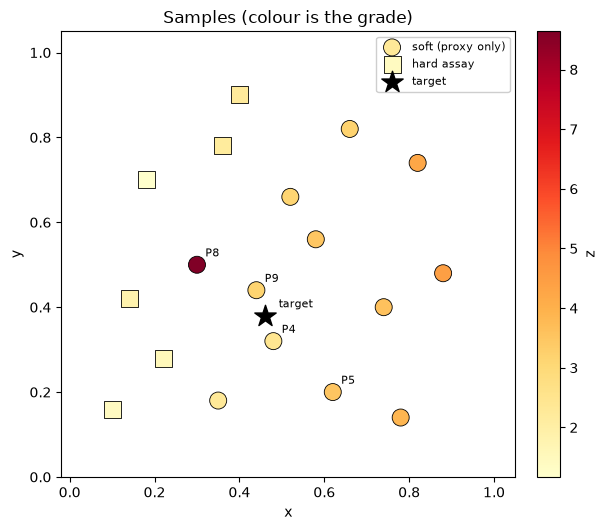

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
hard = samples["role"] == "hard"
sc = ax.scatter(
    samples.loc[~hard, "x"], samples.loc[~hard, "y"],
    c=samples.loc[~hard, "z"], cmap="YlOrRd", vmin=z.min(), vmax=z.max(),
    s=150, marker="o", edgecolors="k", linewidths=0.6, zorder=3, label="soft (proxy only)",
)
ax.scatter(
    samples.loc[hard, "x"], samples.loc[hard, "y"],
    c=samples.loc[hard, "z"], cmap="YlOrRd", vmin=z.min(), vmax=z.max(),
    s=150, marker="s", edgecolors="k", linewidths=0.6, zorder=3, label="hard assay",
)
for _, row in samples.iterrows():
    if row["point"] in {"P4", "P5", "P8", "P9"}:
        ax.annotate(
            row["point"],
            (row["x"], row["y"]),
            textcoords="offset points",
            xytext=(6, 6),
            fontsize=8,
        )
ax.scatter(target_xy[0, 0], target_xy[0, 1], marker="*", s=260, c="k", zorder=4, label="target")
ax.annotate(
    "target",
    (target_xy[0, 0], target_xy[0, 1]),
    textcoords="offset points", xytext=(10, 6), fontsize=8,
)
ax.set_xlim(-0.02, 1.05)
ax.set_ylim(0.00, 1.05)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Samples (colour is the grade)")
ax.legend(frameon=True, loc="upper right", fontsize=8, framealpha=0.95)
plt.colorbar(sc, ax=ax, label="z", fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


---

## Five answers at one target

The map-view covariances are the spherical models in the table above. `DisjunctiveKriging` is the exception: it fits the variogram of the normal scores during `fit`. Factorial kriging is told the nested split, $35\%$ of the structured variance at range $0.22$ and $65\%$ at range $0.85$, on top of a nugget of $0.20$.

Soft probabilities come from a fixed logistic of the proxy,

$$
F = \bigl(1 + \exp(-(q - 1.55) / 0.30)\bigr)^{-1},
$$

and the Markov-Bayes coefficient is set to $B = 0.70$. A sample of indicators that are all zero has $\mathrm{Cov}(I, F) = 0$, so $B$ is not identified from these six hard assays. The soft-kriging notebook estimates $B$ from a mixed set of exceedances and non-exceedances. Here the coefficient is an input, and the comparison is hard-only indicator kriging of those six assays against the combined system.


Six nearest in map view
point    z  depth   map  h_3d  I
   P4 2.44    1.4 0.063 2.502  0
   P9 3.18    1.6 0.063 3.001  0
   P8 8.64    0.5 0.200 0.380  1
  P10 3.49    0.2 0.216 0.588  0
   P3 2.29    0.6 0.228 0.597  0
   P5 3.53    0.4 0.241 0.344  1

Six nearest in the 3-D anisotropy metric (a value of 1 is one range)
point    z  depth   map  h_3d  I
   P5 3.53    0.4 0.241 0.344  1
   P8 8.64    0.5 0.200 0.380  1
  P15 3.13    0.4 0.286 0.409  0
  P10 3.49    0.2 0.216 0.588  0
   P3 2.29    0.6 0.228 0.597  0
   P1 1.41    0.3 0.422 0.653  0

predictor                       value   second
formula, depth 0.40             3.148         
ordinary kriging                3.033 SE 0.746
kt3d, map view                  3.036 SE 0.747
kt3d, depth 0.40                4.651 SE 1.228
disjunctive kriging             2.666 SE 1.039
factorial total                 2.794         
indicator P(Z>=3.5)             0.056 at P8 1.000
hard-only indicator             0.000         
soft kriging, B=0

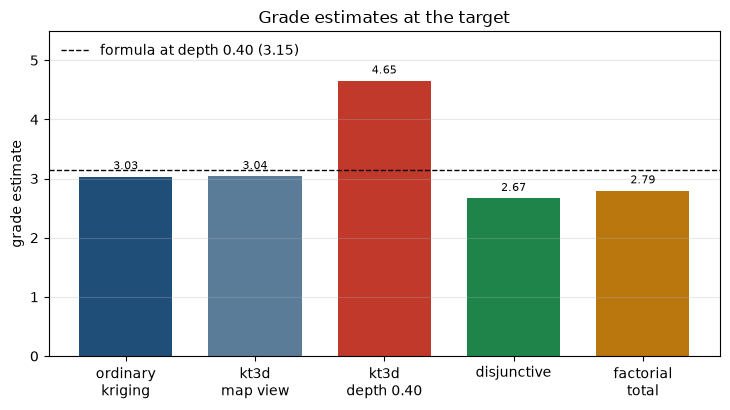

In [4]:
var_z = float(np.var(z))
p_cut = float(np.mean(z >= cutoff))
nugget_i, range_i = 0.02, 0.55
sill_i = p_cut * (1.0 - p_cut) - nugget_i
indicator_model = {cutoff: (nugget_i, sill_i, range_i)}

# --- ordinary kriging of the grade, the reference ---
vg_z = Variogram(coords, z, model="spherical", n_lags=4, use_gpu=False)
vg_z.set_params(nugget=0.15, sill=var_z - 0.15, range_=0.70)
z_ok, se_ok = OrdinaryKriging(vg_z, use_gpu=USE_GPU).fit(coords, z).predict(
    target_xy, return_variance=True
)
z_ok, se_ok = float(z_ok[0]), float(se_ok[0])

# --- indicator kriging: one cutoff, at the target and at the hotspot ---
ik = IndicatorKriging(cov_model="spherical", max_neighbors=8, use_gpu=USE_GPU).fit(coords, z)
p_target = float(ik.predict(target_xy, [cutoff], indicator_model)[cutoff][0])
p_hot = float(ik.predict(hotspot, [cutoff], indicator_model)[cutoff][0])

# --- 3-D ordinary kriging, and the same call with the depth ignored ---
grades = pd.DataFrame({
    "x": samples["x"], "y": samples["y"], "depth": samples["depth"], "grade": z,
})
partial = var_z - 0.15
vg_3d = {
    "nugget": 0.15,
    "structures": [{
        "type": "spherical",
        "sill": partial,
        "range": 0.70,
        "range2": 0.70,
        "range3": 0.40,
        "angles": (0.0, 0.0, 0.0),
    }],
}
kt_3d = kt3d(
    grades, x="x", y="y", z="depth", value="grade",
    points=target_3d, variogram=vg_3d, ktype="ordinary",
    search_radius=2.0, search_radius2=2.0, search_radius3=2.0,
    ndmax=12, use_gpu=USE_GPU,
)
kt_2d = kt3d(
    grades, x="x", y="y", value="grade",
    points=target_xy,
    variogram={"nugget": 0.15, "structures": [{"type": "spherical", "sill": partial, "range": 0.70}]},
    ktype="ordinary", search_radius=2.0, ndmax=12, use_gpu=USE_GPU,
)
z_3d = float(kt_3d["estimate"].iloc[0])
se_3d = float(np.sqrt(kt_3d["variance"].iloc[0]))
z_2d = float(kt_2d["estimate"].iloc[0])
se_2d = float(np.sqrt(kt_2d["variance"].iloc[0]))

# Anisotropic distance: horizontal ranges 0.70, vertical range 0.40.
h_3d = np.sqrt(
    ((coords[:, 0] - target_xy[0, 0]) / 0.70) ** 2
    + ((coords[:, 1] - target_xy[0, 1]) / 0.70) ** 2
    + ((depth - target_depth) / 0.40) ** 2
)
map_dist = cdist(target_xy, coords)[0]
rank = pd.DataFrame({
    "point": samples["point"],
    "z": z,
    "depth": depth,
    "map": map_dist,
    "h_3d": h_3d,
    "I": (z >= cutoff).astype(int),
}).sort_values("h_3d")

# --- soft kriging: six hard non-exceedances, twelve soft probabilities ---
hard_indicator = (z[hard_idx] >= cutoff).astype(float)
soft_prob = 1.0 / (1.0 + np.exp(-(proxy[soft_idx] - 1.55) / 0.30))
B = 0.70
ik_hard = IndicatorKriging(cov_model="spherical", max_neighbors=6, use_gpu=USE_GPU)
ik_hard.fit(coords[hard_idx], z[hard_idx])
p_hard = float(ik_hard.predict(target_xy, [cutoff], indicator_model)[cutoff][0])
sk = SoftKriging(
    cov_model="spherical", max_neighbors_hard=6, max_neighbors_soft=6, use_gpu=USE_GPU,
)
sk.fit(coords[hard_idx], hard_indicator, coords[soft_idx], soft_prob, B=B)
p_soft = float(np.atleast_1d(sk.predict(
    target_xy, sill=sill_i, range_=range_i, nugget=nugget_i,
))[0])

# --- disjunctive kriging: the class fits the normal-score variogram ---
dk = DisjunctiveKriging(
    model="spherical", n_hermite=6, use_gpu=USE_GPU, variogram_kwargs={"n_lags": 5},
)
dk.fit(coords, z)
z_dk, se_dk = dk.predict(target_xy, return_variance=True)
p_dk = float(dk.predict_proba(target_xy, [cutoff])[cutoff][0])
z_dk, se_dk = float(z_dk[0]), float(se_dk[0])
y_nugget, y_psill, y_range = (float(v) for v in dk.y_variogram_.fitted_params)

# --- factorial kriging: one nested model, several right-hand sides ---
structured = var_z - 0.20
fk = FactorialKriging(
    nugget=0.20,
    structures=[
        {"model": "spherical", "sill": 0.35 * structured, "range": 0.22},
        {"model": "spherical", "sill": 0.65 * structured, "range": 0.85},
    ],
    max_neighbors=18,
    use_gpu=USE_GPU,
).fit(coords, z)

def factors(pt):
    return {
        "total": float(fk.extract(pt, "total")[0]),
        "short": float(fk.extract(pt, 1)[0]),
        "long": float(fk.extract(pt, 2)[0]),
        "denoised": float(fk.extract(pt, "denoised")[0]),
        "nugget": float(fk.extract(pt, "nugget")[0]),
        "short_and_long": float(fk.extract(pt, [1, 2])[0]),
    }

fac_target = factors(target_xy)
fac_hot = factors(hotspot)

shown = rank.round({"z": 2, "depth": 1, "map": 3, "h_3d": 3})
print("Six nearest in map view")
print(shown.sort_values("map").head(6).to_string(index=False))
print()
print("Six nearest in the 3-D anisotropy metric (a value of 1 is one range)")
print(shown.head(6).to_string(index=False))
print()
print(f"{'predictor':<28} {'value':>8} {'second':>8}")
rows = [
    ("formula, depth 0.40", z_formula, ""),
    ("ordinary kriging", z_ok, f"SE {se_ok:.3f}"),
    ("kt3d, map view", z_2d, f"SE {se_2d:.3f}"),
    ("kt3d, depth 0.40", z_3d, f"SE {se_3d:.3f}"),
    ("disjunctive kriging", z_dk, f"SE {se_dk:.3f}"),
    ("factorial total", fac_target["total"], ""),
    (f"indicator P(Z>={cutoff})", p_target, f"at P8 {p_hot:.3f}"),
    ("hard-only indicator", p_hard, ""),
    (f"soft kriging, B={B:.2f}", p_soft, ""),
    ("disjunctive P(Z>=3.5)", p_dk, f"Y range {y_range:.3f}"),
]
for name, value, second in rows:
    print(f"{name:<28} {value:8.3f} {second:>8}")
print()
print(f"DK explained variance ratio {dk.explained_variance_ratio_:.3f}")
print(f"Y variogram  nugget {y_nugget:.3f}  partial sill {y_psill:.3f}  range {y_range:.3f}")
print()
print("Factorial factors")
fac = pd.DataFrame({"target": fac_target, "P8": fac_hot}).T
print(fac.round(3).to_string())
print()
print(
    "additivity at the target: "
    f"extract([1, 2]) = {fac_target['short_and_long']:.6f}    "
    f"extract(1)+extract(2) = {fac_target['short'] + fac_target['long']:.6f}"
)

fig, ax = plt.subplots(figsize=(7.4, 4.2))
names = ["ordinary\nkriging", "kt3d\nmap view", "kt3d\ndepth 0.40", "disjunctive", "factorial\ntotal"]
values = [z_ok, z_2d, z_3d, z_dk, fac_target["total"]]
colors = ["#1f4e79", "#5b7c99", "#c0392b", "#1e8449", "#b9770e"]
bars = ax.bar(names, values, color=colors, width=0.72)
ax.axhline(z_formula, color="k", lw=1.0, ls="--", label=f"formula at depth 0.40 ({z_formula:.2f})")
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.08, f"{val:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("grade estimate")
ax.set_title("Grade estimates at the target")
ax.set_ylim(0, max(values + [z_formula]) * 1.18)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


---

## How to read the five answers

The formula at depth $0.40$ is $3.148$. Ordinary kriging of the grade returns $3.033$, with standard error $0.746$. The two nearest samples in the map, P4 and P9, are $0.063$ away and carry grades $2.44$ and $3.18$, so a linear average of neighbours lands just under $3.1$. Map-view `kt3d` returns $3.036$ and standard error $0.747$. It is the same spherical model, using the twelve nearest samples. The two calls agree.

**Indicator kriging** answers a different question. $P[Z \ge 3.5]$ at the target is $0.056$, against a marginal rate of $0.333$. Six samples exceed $3.5$, and three of the eight nearest in the map do, but the two closest indicators are $0$. Those two dominate the indicator system. At P8, where the sample itself is $8.64$, the same cutoff returns a probability of $1$. A cutoff probability follows the local indicators: near $0$ beside non-exceedances, and near $1$ on the hotspot.

**3-D kriging** uses the same grades and a vertical range of $0.40$. At depth $0.40$ the estimate is $4.651$, with standard error $1.228$. The anisotropy metric rescales depth by $1/0.40$ and the map coordinates by $1/0.70$, so a value of $1$ is one range. In that metric P4 and P9, the map-view neighbours, sit at distances $2.50$ and $3.00$. Almost all of that distance is depth, past one vertical range, so their covariance with the target is zero. The nearest samples are then P5 (grade $3.53$, the same depth as the target, anisotropic distance $0.344$) and P8 (grade $8.64$, anisotropic distance $0.380$). The hotspot is inside the neighbourhood, and the estimate rises from about $3.0$ to $4.65$. The standard error stays large because that neighbourhood is thin. Two samples a short step apart on the map, and a long step apart in depth, are different neighbours once the vertical range is the short one.

**Soft kriging** uses only the six hard assays. All six fall below $3.5$, their indicators are all $0$, and ordinary kriging of a constant $0$ with weights summing to $1$ returns $0$. With $B = 0.70$ the combined system returns $0.459$. The soft probabilities at the nearby proxy locations, including a value near $1$ at P8, are what produce that probability. $B$ was set, because six non-exceedances cannot identify it. The soft-kriging notebook estimates $B$ from co-located pairs that do contain both indicators.

**Disjunctive kriging** returns a grade of $2.666$ and standard error $1.039$, and from the same Hermite components a probability $P[Z \ge 3.5] = 0.205$. Six orders capture $0.932$ of the variance of $Z$. The normal-score variogram fitted inside the class has nugget $0$, partial sill $0.899$, and range $0.300$, shorter than the range $0.70$ used for the raw grade. The grade $2.666$ and the probability $0.205$ sit on that fitted covariance of $Y$. The indicator probability $0.056$ sits on the indicator model in the table above. The call shows the shape of the estimator: one fit, a nonlinear grade, and a cutoff probability that reuses the kriged Hermite terms. The disjunctive notebook is where that fitted variogram is judged against ordinary kriging on a real histogram.

**Factorial kriging** at the target returns a total of $2.794$. The short-range factor is $-0.523$ and the long-range factor is $+0.490$. They cancel to $-0.033$, and `extract([1, 2])` matches `extract(1) + extract(2)` to machine precision. The nugget factor at the target is $0$, and the denoised estimate equals the total, $2.794$: no sample sits on the target, so the nugget covariance on the right-hand side is zero. At P8 the total reproduces the sample, $8.640$. The denoised value is $7.863$. The nugget factor is $0.777$, the short-range factor is $3.275$, and the long-range factor is $1.761$. Those three sum to $5.813$. The gap up to $8.640$ is the local mean that the sum-to-zero constraint removed from each factor. The spike at P8 is carried mostly by the short-range structure. That separation is the reason for fitting a nested variogram in the first place.


---

## Where the next notebooks go

The calls above are the five estimators with the covariances either set or, for disjunctive kriging, fitted on eighteen points. What they leave out is a real sampling pattern, a held-out check, and the bookkeeping each method needs before the map is worth trusting.

| Next notebook | What it adds to the call you just ran |
|---|---|
| [Indicator kriging](05_04_01_indicator_kriging.ipynb) | Nine zinc quantiles on the Meuse floodplain, a spherical fit at each cutoff, a Brier score against the marginal frequency, probability maps, and an E-type mean |
| [3-D kriging](05_04_02_kriging_3d.ipynb) | The GSLIB `cluster.dat` benchmark, then borehole grade on a grid: the search ellipsoid, octant search, a depth trend, and point kriging against block kriging |
| [Soft kriging](05_04_03_soft_kriging.ipynb) | A 20% / 80% split of Jura cadmium, a logistic probability from zinc, a calibrated $B$, and held-out AUC and Brier scores against hard-only indicator kriging |
| [Disjunctive kriging](05_04_04_disjunctive_kriging.ipynb) | The normal-score transform and Hermite coefficients of Jura cadmium, a comparison with ordinary kriging, and exceedance maps from `predict_proba` |
| [Factorial kriging](05_04_05_factorial_kriging.ipynb) | A fitted nugget + short + long model of Jura cadmium, maps of each factor, a check that same-constraint factors add, and a denoised grade map |

Open the notebook whose question matches the table at the top. Each one assumes the ordinary-kriging system from the classic-kriging chapter and the one-paragraph version of its own estimator written here.


---

## Resources

### The paper or program behind each estimator

| Reference | Estimator |
|---|---|
| Journel, A.G. (1983). Nonparametric estimation of spatial distributions. *Mathematical Geology* 15, 445-468. | Indicator kriging |
| Deutsch, C.V. & Journel, A.G. (1998). *GSLIB: Geostatistical Software Library and User's Guide* (2nd ed.). Oxford. | `ik3d` and `kt3d`, the reference programs for indicator kriging and 3-D kriging |
| Zhu, H. & Journel, A.G. (1993). Formatting and integrating soft data: stochastic imaging via the Markov-Bayes algorithm. In *Geostatistics Tróia '92*, 1-12. | Soft kriging |
| Matheron, G. (1976). A simple substitute for conditional expectation: the disjunctive kriging. In *Advanced Geostatistics in the Mining Industry*, 221-236. Reidel. | Disjunctive kriging |
| Rivoirard, J. (1994). *Introduction to Disjunctive Kriging and Nonlinear Geostatistics*. Oxford. | The Hermite-polynomial form used by `DisjunctiveKriging` |
| Matheron, G. (1982). *Pour une analyse krigeante des données régionalisées*. Note N-732, Centre de Géostatistique, Fontainebleau. | Factorial kriging |
| Sandjivy, L. (1984). The factorial kriging analysis of regionalized data. In *Geostatistics for Natural Resources Characterization*. Reidel. | Factorial kriging in geochemical mapping |

### Textbooks that cover more than one of them

| Reference | What to read it for |
|---|---|
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford. | Indicator coding, soft data, disjunctive kriging, factorial kriging, and the Jura survey |
| Chilès, J.-P. & Delfiner, P. (2012). *Geostatistics: Modeling Spatial Uncertainty* (2nd ed.). Wiley. | The kriging system, the bi-Gaussian model, and the factorial-kriging constraint |
| Isaaks, E.H. & Srivastava, R.M. (1989). *An Introduction to Applied Geostatistics*. Oxford. | Worked indicator and kriging examples |

### In this library

| Object | Role |
|---|---|
| `IndicatorKriging` | Ordinary indicator kriging, exceedance coding $I(Z \ge z_k)$ |
| `compute_etype_from_probabilities` | E-type mean from a stack of cutoff probabilities |
| `kt3d`, `kt3d_grid`, `kt3d_cross_validate` | 3-D kriging at points, on a grid, and by leave-one-out |
| `SoftKriging` | Markov-Bayes ordinary kriging of hard indicators and soft probabilities |
| `markov_bayes_calibrate` | $B = \mathrm{Cov}(I, F) / \mathrm{Var}(F)$ |
| `fit_soft_probability_model` | Logistic regression from a continuous proxy to $F$ |
| `DisjunctiveKriging` | Hermite disjunctive kriging: `predict` and `predict_proba` |
| `FactorialKriging`, `fit_nested_variogram` | One nested structure at a time, and a fit of that nested model |
| `OrdinaryKriging`, `Variogram` | The linear reference used beside the five calls |
